In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import requests
import zipfile
import re

from pathlib import Path
from tqdm.auto import tqdm

## Download Q1 2021 blackblaze smart dataset

In [3]:
url = (
    "https://f001.backblazeb2.com/file/"
    "Backblaze-Hard-Drive-Data/data_Q1_2021.zip"
)

zip_path = Path("/content/data_Q1_2021.zip")

if zip_path.exists() and zipfile.is_zipfile(zip_path):
    print("Dataset is already downloaded.")
else:
    with requests.get(url, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()

        total = int(response.headers.get("content-length", 0))

        with open(zip_path, "wb") as output:
            with tqdm(total=total, unit="B", unit_scale=True) as progress:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        output.write(chunk)
                        progress.update(len(chunk))

    if not zipfile.is_zipfile(zip_path):
        raise ValueError("Download did not produce a valid ZIP file.")

    print("Download complete.")

  0%|          | 0.00/890M [00:00<?, ?B/s]

Download complete.


## Finding the daily CSV files without extracting the entire zip file

In [4]:
archive = zipfile.ZipFile(zip_path)

daily_files = sorted(
    name
    for name in archive.namelist()
    if "__MACOSX" not in name
    and re.fullmatch(
        r"\d{4}-\d{2}-\d{2}\.csv",
        Path(name).name
    )
)

if not daily_files:
    raise ValueError("No daily CSV files were found.")

selected_files = daily_files[:30]

print("Daily files available:", len(daily_files))
print("Files selected:", len(selected_files))
print("First:", Path(selected_files[0]).name)
print("Last:", Path(selected_files[-1]).name)

Daily files available: 90
Files selected: 30
First: 2021-01-01.csv
Last: 2021-01-30.csv


## Inspecting the 1st day

In [5]:
wanted_columns = [
    "date",
    "serial_number",
    "model",
    "smart_5_raw",
    "smart_9_raw",
    "smart_194_raw",
    "smart_197_raw",
    "smart_198_raw"
]

with archive.open(selected_files[0]) as csv_file:
    first_day = pd.read_csv(
        csv_file,
        usecols=lambda column: column in wanted_columns
    )

print("Drives recorded on the first day:", len(first_day))
display(first_day.head())

print("\nMost common models:")
display(first_day["model"].value_counts().head(15))

Drives recorded on the first day: 165512


,date,serial_number,model,smart_5_raw,smart_9_raw,smart_194_raw,smart_197_raw,smart_198_raw
0,2021-01-01,ZLW0EGC6,ST12000NM001G,0.0,5059.0,29.0,0.0,0.0
1,2021-01-01,Z305B2QN,ST4000DM000,0.0,44255.0,20.0,0.0,0.0
2,2021-01-01,ZLW0C6NE,ST12000NM001G,0.0,5460.0,39.0,0.0,0.0
3,2021-01-01,ZJV0XJQ3,ST12000NM0007,0.0,18325.0,34.0,0.0,0.0
4,2021-01-01,ZLW18MKT,ST14000NM001G,0.0,1178.0,27.0,0.0,0.0



Most common models:


,count
model,
ST12000NM0007,23036
TOSHIBA MG07ACA14TA,21027
ST12000NM0008,19287
ST4000DM000,18939
ST8000NM0055,14406
HGST HMS5C4040BLE640,12744
HGST HUH721212ALN604,10830
ST8000DM002,9770
ST12000NM001G,7130


## Selecting ST12000NM0008 as the initial HDD model

In [6]:
MODEL = "ST12000NM0008"

model_rows = first_day.loc[
    first_day["model"] == MODEL
].copy()

if model_rows.empty:
    raise ValueError(
        "This model is absent. Replace MODEL with an HDD model "
        "shown in the previous cell."
    )

# Prefer a drive with more observed candidate SMART readings.
smart_columns = [
    column for column in wanted_columns
    if column.startswith("smart_") and column in model_rows.columns
]

if not smart_columns:
    raise ValueError("No candidate SMART columns are available.")

completeness = model_rows[smart_columns].notna().sum(axis=1)

chosen_index = completeness.idxmax()
drive_id = model_rows.loc[chosen_index, "serial_number"]

print("Selected model:", MODEL)
print("Selected drive:", drive_id)

display(model_rows.loc[[chosen_index]])

Selected model: ST12000NM0008
Selected drive: ZHZ50GCV


,date,serial_number,model,smart_5_raw,smart_9_raw,smart_194_raw,smart_197_raw,smart_198_raw
15,2021-01-01,ZHZ50GCV,ST12000NM0008,0.0,8741.0,34.0,0.0,0.0


## Collect ST12000NM0008 drive’s history

In [7]:
drive_records = []

for filename in tqdm(selected_files, desc="Reading daily files"):
    with archive.open(filename) as csv_file:
        chunks = pd.read_csv(
            csv_file,
            usecols=lambda column: column in wanted_columns,
            chunksize=50000
        )

        for chunk in chunks:
            matching_rows = chunk.loc[
                chunk["serial_number"] == drive_id
            ]

            if not matching_rows.empty:
                drive_records.append(matching_rows.copy())

if not drive_records:
    raise ValueError("No records were found for the selected drive.")

drive_history = pd.concat(drive_records, ignore_index=True)
drive_history["date"] = pd.to_datetime(drive_history["date"])

duplicate_count = drive_history.duplicated(
    subset=["serial_number", "date"]
).sum()

print("Duplicate drive-date records:", duplicate_count)

if duplicate_count:
    raise ValueError("Inspect duplicate records before plotting.")

drive_history = drive_history.sort_values("date").reset_index(drop=True)

print("Drive:", drive_id)
print("Model:", MODEL)
print("Observed days:", len(drive_history))

display(drive_history.head())

Reading daily files:   0%|          | 0/30 [00:00<?, ?it/s]

Duplicate drive-date records: 0
Drive: ZHZ50GCV
Model: ST12000NM0008
Observed days: 30


,date,serial_number,model,smart_5_raw,smart_9_raw,smart_194_raw,smart_197_raw,smart_198_raw
0,2021-01-01,ZHZ50GCV,ST12000NM0008,0.0,8741.0,34.0,0.0,0.0
1,2021-01-02,ZHZ50GCV,ST12000NM0008,0.0,8757.0,34.0,0.0,0.0
2,2021-01-03,ZHZ50GCV,ST12000NM0008,0.0,8789.0,34.0,0.0,0.0
3,2021-01-04,ZHZ50GCV,ST12000NM0008,0.0,8805.0,34.0,0.0,0.0
4,2021-01-05,ZHZ50GCV,ST12000NM0008,0.0,8838.0,35.0,0.0,0.0


## Check missing readings

In [8]:
available_smart = [
    column for column in smart_columns
    if column in drive_history.columns
]

for column in available_smart:
    drive_history[column] = pd.to_numeric(
        drive_history[column],
        errors="coerce"
    )

print("Missing SMART readings:")
display(drive_history[available_smart].isna().sum())

expected_dates = pd.date_range(
    drive_history["date"].min(),
    drive_history["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(drive_history["date"])

print("Missing dates within the observed period:")
print(missing_dates.strftime("%Y-%m-%d").tolist())

Missing SMART readings:


,0
smart_5_raw,0
smart_9_raw,0
smart_194_raw,0
smart_197_raw,0
smart_198_raw,0


Missing dates within the observed period:
[]


**Plot the SMART history**

Use separate plots because the attributes have very different numerical ranges. The code inserts missing dates as blank observations so the graph does not join across a missing day.

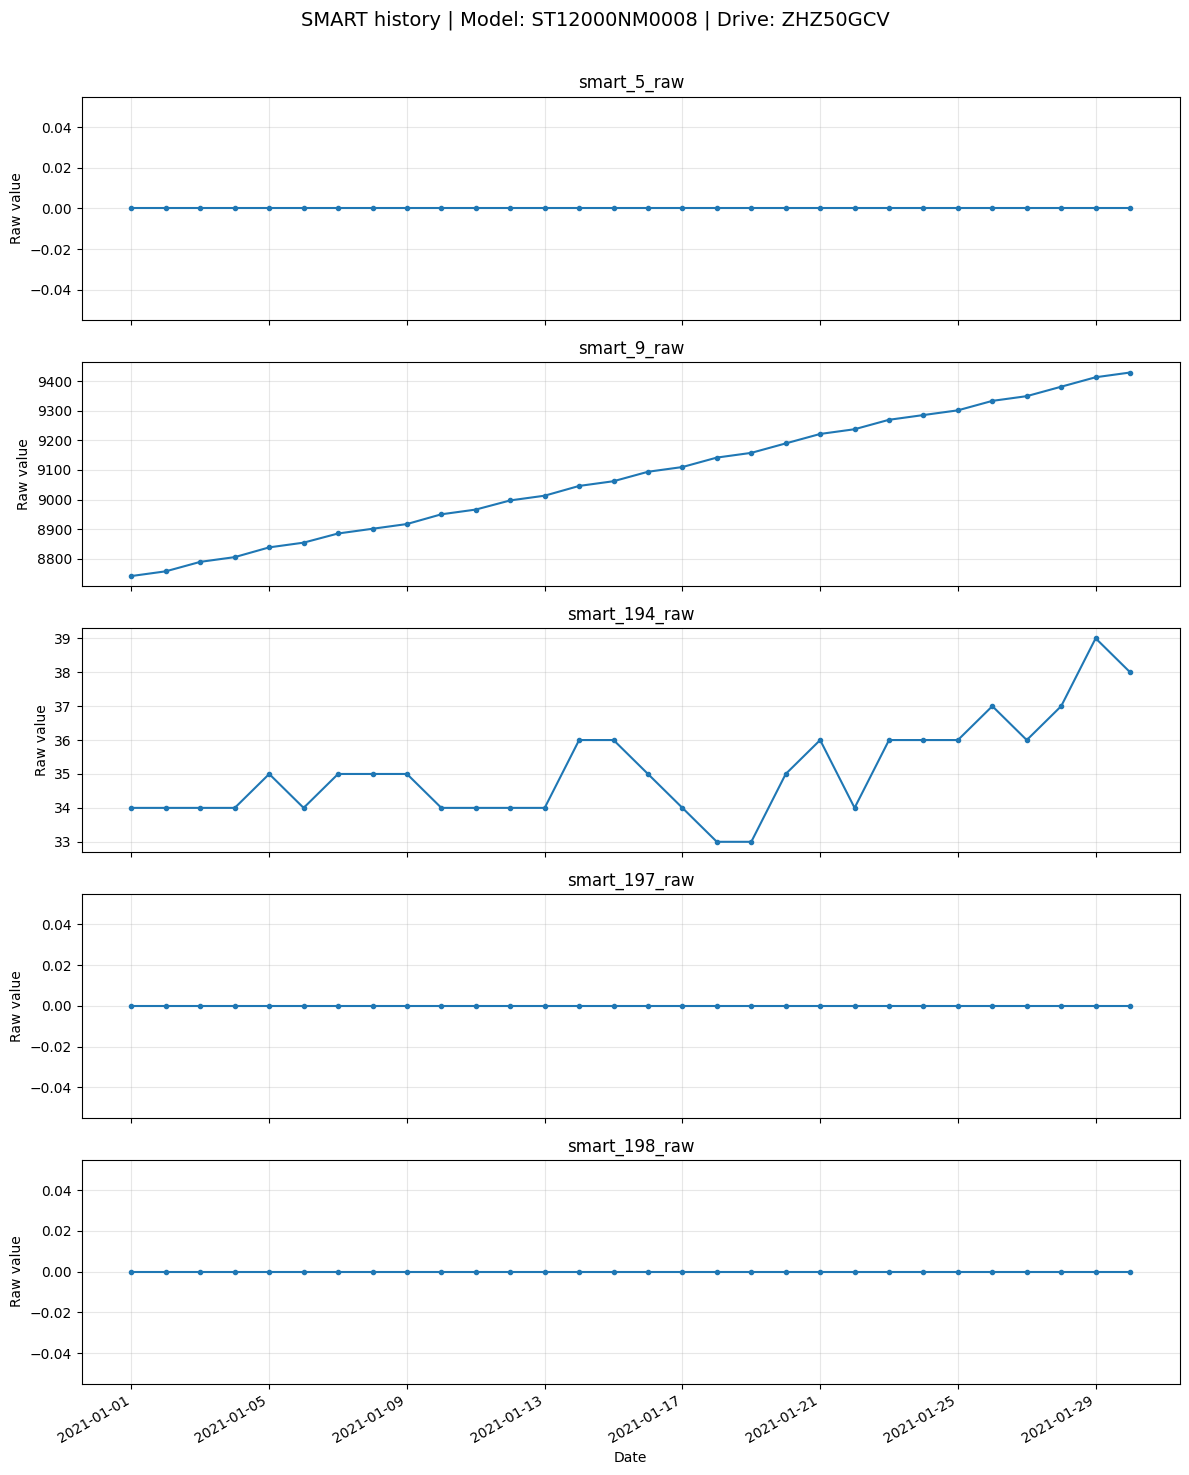

In [9]:
plot_columns = [
    column for column in available_smart
    if drive_history[column].notna().any()
]

if not plot_columns:
    raise ValueError("This drive has no observed candidate SMART readings.")

plot_data = (
    drive_history
    .set_index("date")[plot_columns]
    .reindex(expected_dates)
)

fig, axes = plt.subplots(
    len(plot_columns),
    1,
    figsize=(12, 3 * len(plot_columns)),
    sharex=True,
    squeeze=False
)

for ax, column in zip(axes.flat, plot_columns):
    ax.plot(
        plot_data.index,
        plot_data[column],
        marker="o",
        markersize=3,
        linewidth=1.5
    )

    ax.set_title(column)
    ax.set_ylabel("Raw value")
    ax.grid(alpha=0.3)

axes[-1, 0].set_xlabel("Date")

fig.suptitle(
    f"SMART history | Model: {MODEL} | Drive: {drive_id}",
    fontsize=14
)

fig.autofmt_xdate()
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [10]:
from google.colab import files

drive_history.to_csv("one_drive_history.csv", index=False)

fig.savefig(
    "one_drive_smart_history.png",
    dpi=200,
    bbox_inches="tight"
)

files.download("one_drive_history.csv")
files.download("one_drive_smart_history.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Get exact summary values

In [11]:
summary = drive_history[available_smart].agg(
    ["count", "min", "max", "mean", "std"]
).T

summary["missing"] = drive_history[available_smart].isna().sum()
summary["unique_values"] = drive_history[available_smart].nunique()

display(summary.round(2))

,count,min,max,mean,std,missing,unique_values
smart_5_raw,30.0,0.0,0.0,0.00,0.00,0,1
smart_9_raw,30.0,8741.0,9430.0,9081.43,210.69,0,30
smart_194_raw,30.0,33.0,39.0,35.10,1.42,0,7
smart_197_raw,30.0,0.0,0.0,0.00,0.00,0,1
smart_198_raw,30.0,0.0,0.0,0.00,0.00,0,1


In [12]:
changes = drive_history[
    ["date", "smart_9_raw", "smart_194_raw"]
].copy()

changes["smart_9_daily_change"] = changes["smart_9_raw"].diff()
changes["smart_194_daily_change"] = changes["smart_194_raw"].diff()

display(changes)

,date,smart_9_raw,smart_194_raw,smart_9_daily_change,smart_194_daily_change
0,2021-01-01,8741.0,34.0,NaN,NaN
1,2021-01-02,8757.0,34.0,16.0,0.0
2,2021-01-03,8789.0,34.0,32.0,0.0
3,2021-01-04,8805.0,34.0,16.0,0.0
4,2021-01-05,8838.0,35.0,33.0,1.0
5,2021-01-06,8854.0,34.0,16.0,-1.0
6,2021-01-07,8885.0,35.0,31.0,1.0
7,2021-01-08,8901.0,35.0,16.0,0.0
8,2021-01-09,8917.0,35.0,16.0,0.0
9,2021-01-10,8950.0,34.0,33.0,-1.0


## Select 10 drives reproducibly

In [13]:
candidate_ids = (
    first_day.loc[
        first_day["model"] == MODEL,
        "serial_number"
    ]
    .dropna()
    .drop_duplicates()
)

other_ids = candidate_ids[candidate_ids != drive_id]

sampled_ids = other_ids.sample(
    n=min(9, len(other_ids)),
    random_state=42
).tolist()

selected_drive_ids = [drive_id] + sampled_ids

print("Model:", MODEL)
print("Number of selected drives:", len(selected_drive_ids))
print("Drive IDs:", selected_drive_ids)

Model: ST12000NM0008
Number of selected drives: 10
Drive IDs: ['ZHZ50GCV', 'ZL005C8Q', 'ZHZ6BTK2', 'ZHZ63CYD', 'ZHZ50XBR', 'ZHZ6E3AG', 'ZHZ624AX', 'ZHZ4A36S', 'ZL0051VG', 'ZHZ3QH34']


## Collect their History

In [14]:
records = []

for filename in tqdm(selected_files, desc="Collecting drive histories"):
    with archive.open(filename) as csv_file:
        for chunk in pd.read_csv(
            csv_file,
            usecols=lambda column: column in wanted_columns,
            chunksize=50000
        ):
            matches = chunk.loc[
                chunk["serial_number"].isin(selected_drive_ids)
                & chunk["model"].eq(MODEL)
            ]

            if not matches.empty:
                records.append(matches.copy())

if not records:
    raise ValueError("No matching drive records were found.")

comparison_data = pd.concat(records, ignore_index=True)
comparison_data["date"] = pd.to_datetime(comparison_data["date"])

if comparison_data.duplicated(["serial_number", "date"]).any():
    raise ValueError("Duplicate drive-date records need inspection.")

comparison_data = comparison_data.sort_values(
    ["serial_number", "date"]
).reset_index(drop=True)

comparison_features = [
    column for column in wanted_columns
    if column.startswith("smart_")
    and column in comparison_data.columns
]

for column in comparison_features:
    comparison_data[column] = pd.to_numeric(
        comparison_data[column],
        errors="coerce"
    )

coverage = (
    comparison_data.groupby("serial_number")["date"]
    .nunique()
    .reindex(selected_drive_ids, fill_value=0)
    .rename("observed_days")
)

print("Observed days per selected drive:")
display(coverage)

print("Missing attribute readings within recorded rows:")
display(
    comparison_data.groupby("serial_number")[comparison_features]
    .agg(lambda values: values.isna().sum())
)

Observed days per selected drive:


,observed_days
serial_number,
ZHZ50GCV,30
ZL005C8Q,30
ZHZ6BTK2,30
ZHZ63CYD,30
ZHZ50XBR,30
ZHZ6E3AG,30
ZHZ624AX,30
ZHZ4A36S,30
ZL0051VG,30


Missing attribute readings within recorded rows:


,smart_5_raw,smart_9_raw,smart_194_raw,smart_197_raw,smart_198_raw
serial_number,,,,,
ZHZ3QH34,0,0,0,0,0
ZHZ4A36S,0,0,0,0,0
ZHZ50GCV,0,0,0,0,0
ZHZ50XBR,0,0,0,0,0
ZHZ624AX,0,0,0,0,0
ZHZ63CYD,0,0,0,0,0
ZHZ6BTK2,0,0,0,0,0
ZHZ6E3AG,0,0,0,0,0
ZL0051VG,0,0,0,0,0


## Plot SMART 194 and changes in SMART 9

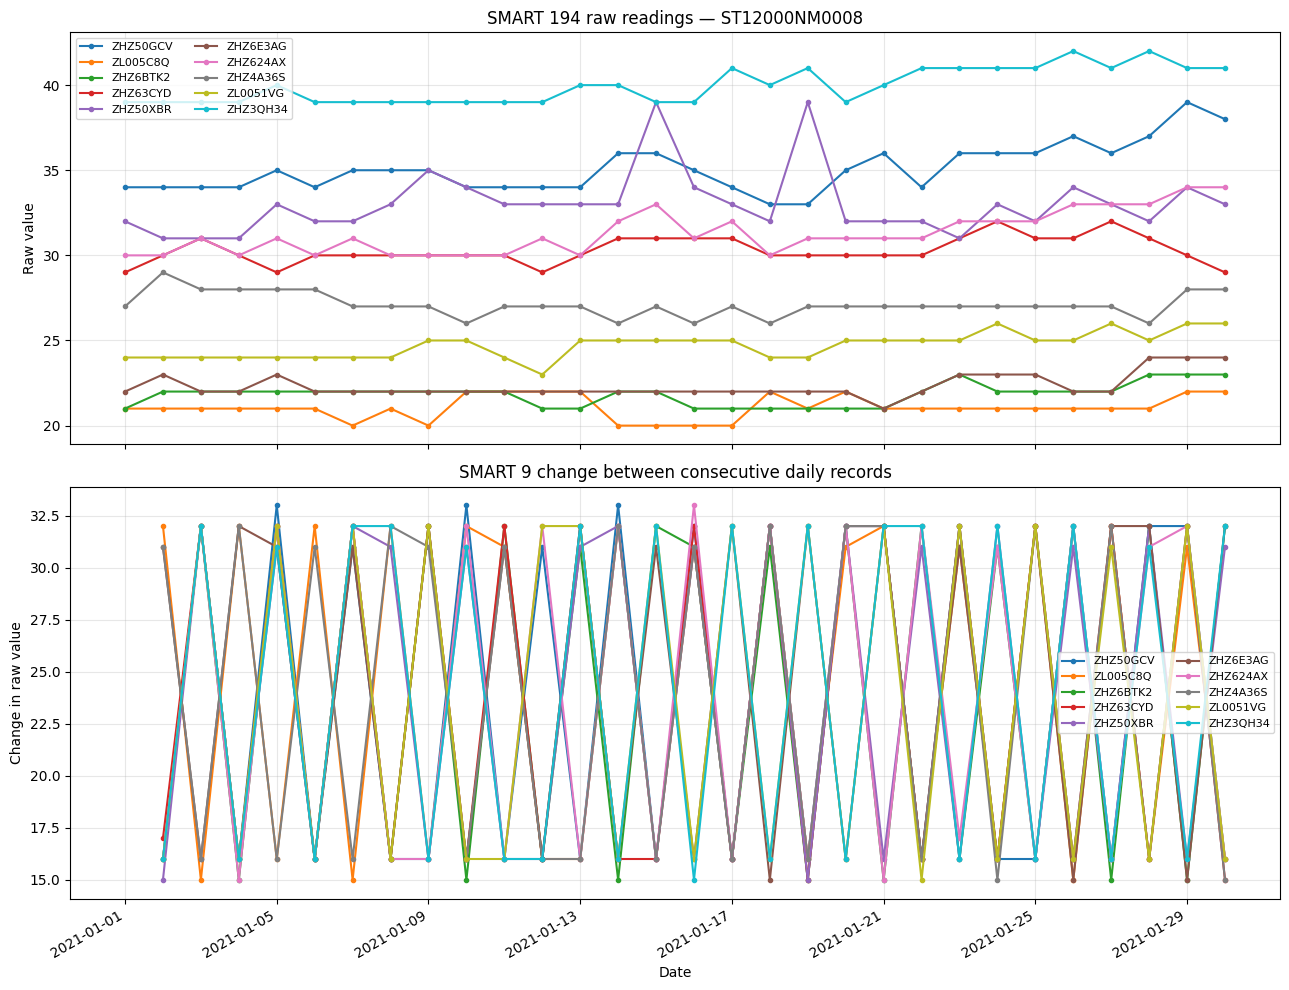

In [15]:
comparison_dates = pd.DatetimeIndex(
    sorted(
        pd.to_datetime(Path(name).stem)
        for name in selected_files
    )
)

fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

for serial in selected_drive_ids:
    history = (
        comparison_data.loc[
            comparison_data["serial_number"] == serial
        ]
        .set_index("date")
        .reindex(comparison_dates)
    )

    axes[0].plot(
        history.index,
        history["smart_194_raw"],
        marker=".",
        label=serial
    )

    axes[1].plot(
        history.index,
        history["smart_9_raw"].diff(),
        marker=".",
        label=serial
    )

axes[0].set_title(f"SMART 194 raw readings — {MODEL}")
axes[0].set_ylabel("Raw value")

axes[1].set_title("SMART 9 change between consecutive daily records")
axes[1].set_ylabel("Change in raw value")
axes[1].set_xlabel("Date")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [16]:
comparison_data.to_csv("ten_drive_histories.csv", index=False)
fig.savefig("ten_drive_comparison.png", dpi=200, bbox_inches="tight")

files.download("ten_drive_histories.csv")
files.download("ten_drive_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Expand to 1,000 drives over the full available quarter

In [17]:
MODEL = "ST12000NM0008"
SAMPLE_SIZE = 1000
SEED = 42

candidate_ids = (
    first_day.loc[first_day["model"].eq(MODEL), "serial_number"]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

other_ids = candidate_ids[candidate_ids != drive_id]

pilot_drive_ids = [drive_id] + other_ids.sample(
    n=min(SAMPLE_SIZE - 1, len(other_ids)),
    random_state=SEED
).tolist()

pilot_files = daily_files

print("Selected drives:", len(pilot_drive_ids))
print("Daily files:", len(pilot_files))
print("First file:", Path(pilot_files[0]).name)
print("Last file:", Path(pilot_files[-1]).name)

Selected drives: 1000
Daily files: 90
First file: 2021-01-01.csv
Last file: 2021-03-31.csv


## Collect the quarter’s readings

In [18]:
pilot_records = []

for filename in tqdm(pilot_files, desc="Building pilot dataset"):
    with archive.open(filename) as csv_file:
        for chunk in pd.read_csv(
            csv_file,
            usecols=lambda column: column in wanted_columns,
            chunksize=50000
        ):
            matches = chunk.loc[
                chunk["model"].eq(MODEL)
                & chunk["serial_number"].isin(pilot_drive_ids)
            ]

            if not matches.empty:
                pilot_records.append(matches.copy())

if not pilot_records:
    raise ValueError("No matching records were found.")

pilot_data = pd.concat(pilot_records, ignore_index=True)
pilot_data["date"] = pd.to_datetime(pilot_data["date"])

pilot_features = [
    column for column in wanted_columns
    if column.startswith("smart_") and column in pilot_data.columns
]

for column in pilot_features:
    pilot_data[column] = pd.to_numeric(
        pilot_data[column], errors="coerce"
    )

pilot_data = pilot_data.sort_values(
    ["serial_number", "date"]
).reset_index(drop=True)

print("Rows:", len(pilot_data))
print("Drives:", pilot_data["serial_number"].nunique())
print("Date range:", pilot_data["date"].min(), "to",
      pilot_data["date"].max())

Building pilot dataset:   0%|          | 0/90 [00:00<?, ?it/s]

Rows: 89896
Drives: 1000
Date range: 2021-01-01 00:00:00 to 2021-03-31 00:00:00


## Audit the larger dataset

In [19]:
duplicates = pilot_data.duplicated(
    ["serial_number", "date"]
).sum()

print("Duplicate drive-date records:", duplicates)

if duplicates:
    raise ValueError("Inspect duplicate records before continuing.")

pilot_coverage = (
    pilot_data.groupby("serial_number")["date"]
    .nunique()
    .reindex(pilot_drive_ids, fill_value=0)
    .rename("observed_days")
)

pilot_audit = pd.DataFrame({
    "observed_values": pilot_data[pilot_features].count(),
    "missing_values": pilot_data[pilot_features].isna().sum(),
    "missing_percent": (
        pilot_data[pilot_features].isna().mean() * 100
    ),
    "unique_values": pilot_data[pilot_features].nunique(),
    "minimum": pilot_data[pilot_features].min(),
    "maximum": pilot_data[pilot_features].max()
})

print("\nAttribute audit:")
display(pilot_audit.round(2))

print("\nDrive coverage summary:")
display(pilot_coverage.describe())

print("\nNumber of drives by observed-day count:")
display(pilot_coverage.value_counts().sort_index())

Duplicate drive-date records: 0

Attribute audit:


,observed_values,missing_values,missing_percent,unique_values,minimum,maximum
smart_5_raw,89894,2,0.0,91,0.0,10464.0
smart_9_raw,89894,2,0.0,11328,569.0,12944.0
smart_194_raw,89894,2,0.0,38,17.0,56.0
smart_197_raw,89894,2,0.0,22,0.0,616.0
smart_198_raw,89894,2,0.0,22,0.0,616.0



Drive coverage summary:


,observed_days
count,1000.000000
mean,89.896000
std,1.889114
min,39.000000
25%,90.000000
50%,90.000000
75%,90.000000
max,90.000000



Number of drives by observed-day count:


,count
observed_days,
39,1
61,1
80,1
85,1
89,9
90,987


In [20]:
pilot_data.to_csv("hdd_pilot_q1_2021.csv", index=False)
pilot_audit.to_csv("hdd_pilot_feature_audit.csv")
pilot_coverage.to_csv("hdd_pilot_drive_coverage.csv")

files.download("hdd_pilot_q1_2021.csv")
files.download("hdd_pilot_feature_audit.csv")
files.download("hdd_pilot_drive_coverage.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Locate the missing readings

In [21]:
missing_rows = pilot_data.loc[
    pilot_data[pilot_features].isna().any(axis=1)
]

print("Rows with at least one missing SMART reading:")
display(missing_rows)

print("Missing percentages with more precision:")
display(
    (pilot_data[pilot_features].isna().mean() * 100)
    .round(6)
    .rename("missing_percent")
)

Rows with at least one missing SMART reading:


,date,serial_number,model,smart_5_raw,smart_9_raw,smart_194_raw,smart_197_raw,smart_198_raw
31064,2021-01-15,ZHZ4XS47,ST12000NM0008,NaN,NaN,NaN,NaN,NaN
77609,2021-02-13,ZL00564A,ST12000NM0008,NaN,NaN,NaN,NaN,NaN


Missing percentages with more precision:


,missing_percent
smart_5_raw,0.002225
smart_9_raw,0.002225
smart_194_raw,0.002225
smart_197_raw,0.002225
smart_198_raw,0.002225


## Inspect incomplete drive histories

In [22]:
expected_dates = pd.DatetimeIndex(
    sorted({
        pd.Timestamp(Path(name).stem)
        for name in pilot_files
    })
)

coverage_records = []

for serial in pilot_drive_ids:
    observed = pd.DatetimeIndex(
        pilot_data.loc[
            pilot_data["serial_number"].eq(serial), "date"
        ].drop_duplicates().sort_values()
    )

    if len(observed):
        within_history = expected_dates[
            (expected_dates >= observed.min())
            & (expected_dates <= observed.max())
        ]

        coverage_records.append({
            "serial_number": serial,
            "observed_days": len(observed),
            "first_date": observed.min(),
            "last_date": observed.max(),
            "missing_inside_history": len(
                within_history.difference(observed)
            ),
            "missing_across_quarter": len(
                expected_dates.difference(observed)
            )
        })
    else:
        coverage_records.append({
            "serial_number": serial,
            "observed_days": 0,
            "first_date": pd.NaT,
            "last_date": pd.NaT,
            "missing_inside_history": 0,
            "missing_across_quarter": len(expected_dates)
        })

coverage_detail = pd.DataFrame(coverage_records)

incomplete_drives = coverage_detail.loc[
    coverage_detail["missing_across_quarter"] > 0
].sort_values("observed_days")

print("Expected dates in the archive:", len(expected_dates))
print("Drives with incomplete quarter coverage:",
      len(incomplete_drives))

display(incomplete_drives)

print(
    "Total absent drive-date combinations:",
    coverage_detail["missing_across_quarter"].sum()
)

Expected dates in the archive: 90
Drives with incomplete quarter coverage: 13


,serial_number,observed_days,first_date,last_date,missing_inside_history,missing_across_quarter
354,ZHZ445S7,39,2021-01-01,2021-02-09,1,51
390,ZHZ49JJM,61,2021-01-01,2021-03-02,0,29
632,ZHZ4VJJ9,80,2021-01-01,2021-03-21,0,10
794,ZL0051QY,85,2021-01-01,2021-03-26,0,5
347,ZHZ64DGE,89,2021-01-01,2021-03-31,1,1
151,ZHZ65NR1,89,2021-01-01,2021-03-31,1,1
526,ZHZ65Y0K,89,2021-01-01,2021-03-31,1,1
117,ZHZ63RN8,89,2021-01-01,2021-03-31,1,1
542,ZHZ65BY6,89,2021-01-01,2021-03-31,1,1
760,ZHZ669JQ,89,2021-01-01,2021-03-31,1,1


Total absent drive-date combinations: 104


## Check how widely the nonzero readings occur

In [23]:
variation_summary = pd.DataFrame({
    "observed_rows": pilot_data[pilot_features].count(),
    "nonzero_rows": pilot_data[pilot_features].apply(
        lambda values: (values.notna() & values.ne(0)).sum()
    ),
    "drives_with_nonzero_readings": [
        pilot_data.loc[
            pilot_data[column].notna()
            & pilot_data[column].ne(0),
            "serial_number"
        ].nunique()
        for column in pilot_features
    ]
})

display(variation_summary)

,observed_rows,nonzero_rows,drives_with_nonzero_readings
smart_5_raw,89894,1292,17
smart_9_raw,89894,89894,1000
smart_194_raw,89894,89894,1000
smart_197_raw,89894,300,7
smart_198_raw,89894,300,7


## Prepare a daily timeline while preserving missingness

In [24]:
import numpy as np

FEATURES = [
    "smart_5_raw",
    "smart_9_raw",
    "smart_194_raw",
    "smart_197_raw",
    "smart_198_raw"
]

source_data = pilot_data.copy()

for column in FEATURES:
    source_data[column] = pd.to_numeric(
        source_data[column], errors="coerce"
    )

assert not source_data.duplicated(
    ["serial_number", "date"]
).any(), "Duplicate drive-date records need inspection."

prepared_parts = []

for serial, history in source_data.groupby("serial_number"):
    history = history.sort_values("date").set_index("date")

    model_name = history["model"].iloc[0]
    history["record_present"] = True

    calendar = pd.date_range(
        history.index.min(),
        history.index.max(),
        freq="D"
    )

    history = history.reindex(calendar)
    history.index.name = "date"

    history["serial_number"] = serial
    history["model"] = model_name
    history["record_present"] = history["record_present"].eq(True)

    for column in FEATURES:
        history[column + "_observed"] = history[column].notna()

    prepared_parts.append(history.reset_index())

prepared_data = pd.concat(
    prepared_parts, ignore_index=True
).sort_values(["serial_number", "date"]).reset_index(drop=True)

print("Original recorded rows:", len(source_data))
print("Rows after inserting internal gaps:", len(prepared_data))
print("Inserted internal dates:",
      (~prepared_data["record_present"]).sum())

Original recorded rows: 89896
Rows after inserting internal gaps: 89906
Inserted internal dates: 10


## Assign separate drives to each pilot group

In [25]:
rng = np.random.default_rng(42)

drive_ids = np.array(sorted(pilot_drive_ids))
rng.shuffle(drive_ids)

n_train = int(len(drive_ids) * 0.70)
n_calibration = int(len(drive_ids) * 0.15)

train_ids = set(drive_ids[:n_train])

calibration_ids = set(
    drive_ids[n_train:n_train + n_calibration]
)

development_ids = set(
    drive_ids[n_train + n_calibration:]
)

assert train_ids.isdisjoint(calibration_ids)
assert train_ids.isdisjoint(development_ids)
assert calibration_ids.isdisjoint(development_ids)

split_frames = {
    "train": prepared_data.loc[
        prepared_data["serial_number"].isin(train_ids)
        & prepared_data["date"].le("2021-02-28")
    ].copy(),

    "calibration": prepared_data.loc[
        prepared_data["serial_number"].isin(calibration_ids)
        & prepared_data["date"].between(
            "2021-03-01", "2021-03-31"
        )
    ].copy(),

    "development": prepared_data.loc[
        prepared_data["serial_number"].isin(development_ids)
        & prepared_data["date"].between(
            "2021-03-01", "2021-03-31"
        )
    ].copy()
}

for name, frame in split_frames.items():
    print(
        name,
        "| drives with records:", frame["serial_number"].nunique(),
        "| daily rows:", len(frame)
    )

train | drives with records: 700 | daily rows: 41300
calibration | drives with records: 149 | daily rows: 4580
development | drives with records: 150 | daily rows: 4650


## Build fully observed 30-day windows

In [26]:
WINDOW_DAYS = 30

def build_windows(frame):
    windows = []
    metadata = []
    candidates = 0
    skipped_missing = 0

    for serial, history in frame.groupby("serial_number"):
        history = history.sort_values("date").reset_index(drop=True)

        for start in range(len(history) - WINDOW_DAYS + 1):
            block = history.iloc[start:start + WINDOW_DAYS]
            candidates += 1

            expected = pd.date_range(
                block["date"].iloc[0],
                periods=WINDOW_DAYS,
                freq="D"
            )

            if not np.array_equal(
                block["date"].to_numpy(),
                expected.to_numpy()
            ):
                raise ValueError("A window is not calendar-consecutive.")

            values = block[FEATURES].to_numpy(dtype=np.float32)

            if not np.isfinite(values).all():
                skipped_missing += 1
                continue

            windows.append(values)
            metadata.append({
                "serial_number": serial,
                "start_date": block["date"].iloc[0],
                "end_date": block["date"].iloc[-1]
            })

    X = (
        np.stack(windows)
        if windows
        else np.empty((0, WINDOW_DAYS, len(FEATURES)),
                      dtype=np.float32)
    )

    meta = pd.DataFrame(
        metadata,
        columns=["serial_number", "start_date", "end_date"]
    )

    audit = {
        "candidate_windows": candidates,
        "accepted_windows": len(X),
        "skipped_missing": skipped_missing
    }

    return X, meta, audit


window_sets = {}
window_audits = {}

for name, frame in split_frames.items():
    X, metadata, audit = build_windows(frame)

    window_sets[name] = {
        "X": X,
        "metadata": metadata
    }
    window_audits[name] = audit

    print(name, "shape:", X.shape)

display(pd.DataFrame(window_audits).T)

train shape: (20985, 30, 5)
calibration shape: (294, 30, 5)
development shape: (294, 30, 5)


,candidate_windows,accepted_windows,skipped_missing
train,21000,20985,15
calibration,294,294,0
development,300,294,6


## Convert each window into numerical summaries

In [27]:
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest

LOG_FEATURES = [
    "smart_5_raw",
    "smart_9_raw",
    "smart_197_raw",
    "smart_198_raw"
]

SUMMARY_NAMES = ["last", "median", "std", "net_change"]

baseline_feature_names = [
    f"{feature}_{summary}"
    for summary in SUMMARY_NAMES
    for feature in FEATURES
]

def summarise_windows(X):
    values = X.astype(np.float64, copy=True)

    if not np.isfinite(values).all():
        raise ValueError("Windows contain missing or infinite values.")

    for feature in LOG_FEATURES:
        index = FEATURES.index(feature)

        if (values[:, :, index] < 0).any():
            raise ValueError(
                f"Negative readings found in {feature}; inspect them first."
            )

        values[:, :, index] = np.log1p(values[:, :, index])

    summaries = np.concatenate([
        values[:, -1, :],
        np.median(values, axis=1),
        np.std(values, axis=1),
        values[:, -1, :] - values[:, 0, :]
    ], axis=1)

    return pd.DataFrame(
        summaries,
        columns=baseline_feature_names
    )


baseline_tables = {
    name: summarise_windows(data["X"])
    for name, data in window_sets.items()
}

for name, table in baseline_tables.items():
    print(name, table.shape)

display(baseline_tables["train"].head())

train (20985, 20)
calibration (294, 20)
development (294, 20)


,smart_5_raw_last,smart_9_raw_last,smart_194_raw_last,smart_197_raw_last,smart_198_raw_last,smart_5_raw_median,smart_9_raw_median,smart_194_raw_median,smart_197_raw_median,smart_198_raw_median,smart_5_raw_std,smart_9_raw_std,smart_194_raw_std,smart_197_raw_std,smart_198_raw_std,smart_5_raw_net_change,smart_9_raw_net_change,smart_194_raw_net_change,smart_197_raw_net_change,smart_198_raw_net_change
0,0.0,9.310638,36.0,0.0,0.0,0.0,9.279306,35.0,0.0,0.0,0.0,0.019311,0.687184,0.0,0.0,0.0,0.063580,2.0,0.0,0.0
1,0.0,9.313438,35.0,0.0,0.0,0.0,9.281543,35.0,0.0,0.0,0.0,0.019294,0.669992,0.0,0.0,0.0,0.064839,1.0,0.0,0.0
2,0.0,9.314881,36.0,0.0,0.0,0.0,9.283776,35.0,0.0,0.0,0.0,0.019194,0.679869,0.0,0.0,0.0,0.063302,2.0,0.0,0.0
3,0.0,9.317759,36.0,0.0,0.0,0.0,9.285957,35.0,0.0,0.0,0.0,0.019178,0.683130,0.0,0.0,0.0,0.064646,2.0,0.0,0.0
4,0.0,9.319195,36.0,0.0,0.0,0.0,9.288134,35.0,0.0,0.0,0.0,0.019078,0.679869,0.0,0.0,0.0,0.063021,2.0,0.0,0.0


## Fit preprocessing using training data only

RobustScaler uses feature medians and interquartile ranges. Here I''m going to fit it once on training data and apply those same parameters to the other groups.
Scaling is not essential for Isolation Forest, but this gives us an explicit preprocessing stage that we can record and reuse.

In [28]:
scaler = RobustScaler()

scaled_tables = {
    "train": scaler.fit_transform(baseline_tables["train"])
}

for name in ["calibration", "development"]:
    scaled_tables[name] = scaler.transform(
        baseline_tables[name]
    )

for name, values in scaled_tables.items():
    assert np.isfinite(values).all(), (
        f"Non-finite values found in {name}"
    )

print("Preprocessing fitted on training data only.")

Preprocessing fitted on training data only.


## Train Isolation Forest

In [29]:
isolation_forest = IsolationForest(
    n_estimators=200,
    max_samples=256,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(scaled_tables["train"])

print("Isolation Forest training completed.")

Isolation Forest training completed.


## Calculate scores and set a pilot threshold

In [30]:
baseline_scores = {
    name: -isolation_forest.score_samples(values)
    for name, values in scaled_tables.items()
}

CALIBRATION_QUANTILE = 0.99

baseline_threshold = float(
    np.quantile(
        baseline_scores["calibration"],
        CALIBRATION_QUANTILE,
        method="higher"
    )
)

baseline_results = {}

for name, scores in baseline_scores.items():
    results = (
        window_sets[name]["metadata"]
        .copy()
        .reset_index(drop=True)
    )

    results["anomaly_score"] = scores
    results["threshold"] = baseline_threshold
    results["is_anomaly_candidate"] = (
        results["anomaly_score"] > baseline_threshold
    )

    baseline_results[name] = results

print("Frozen pilot threshold:", round(baseline_threshold, 6))

score_summary = pd.DataFrame([
    {
        "split": name,
        "windows": len(results),
        "drives_scored": results["serial_number"].nunique(),
        "flagged_windows": int(
            results["is_anomaly_candidate"].sum()
        ),
        "flagged_percent": (
            results["is_anomaly_candidate"].mean() * 100
        ),
        "drives_with_flags": results.loc[
            results["is_anomaly_candidate"],
            "serial_number"
        ].nunique()
    }
    for name, results in baseline_results.items()
])

display(score_summary.round(3))

Frozen pilot threshold: 0.593071


,split,windows,drives_scored,flagged_windows,flagged_percent,drives_with_flags
0,train,20985,700,453,2.159,25
1,calibration,294,147,2,0.680,1
2,development,294,147,2,0.680,1


## Inspect the highest-scoring development windows

In [31]:
development_results = baseline_results["development"]

top_indices = (
    development_results["anomaly_score"]
    .sort_values(ascending=False)
    .head(10)
    .index
)

top_windows = pd.concat([
    development_results.loc[top_indices],
    baseline_tables["development"].loc[top_indices]
], axis=1)

display(top_windows)

,serial_number,start_date,end_date,anomaly_score,threshold,is_anomaly_candidate,smart_5_raw_last,smart_9_raw_last,smart_194_raw_last,smart_197_raw_last,...,smart_5_raw_std,smart_9_raw_std,smart_194_raw_std,smart_197_raw_std,smart_198_raw_std,smart_5_raw_net_change,smart_9_raw_net_change,smart_194_raw_net_change,smart_197_raw_net_change,smart_198_raw_net_change
29,ZHZ3PXGC,2021-03-02,2021-03-31,0.667930,0.593071,True,7.617268,9.468310,28.0,2.197225,...,2.664535e-15,0.016600,0.771722,4.440892e-16,4.440892e-16,0.0,0.055519,1.0,0.0,0.0
28,ZHZ3PXGC,2021-03-01,2021-03-30,0.664636,0.593071,True,7.617268,9.465912,27.0,2.197225,...,2.664535e-15,0.016626,0.771722,4.440892e-16,4.440892e-16,0.0,0.055738,-1.0,0.0,0.0
247,ZL0052YL,2021-03-02,2021-03-31,0.571105,0.593071,False,0.000000,8.749574,48.0,0.000000,...,0.000000e+00,0.034667,3.119117,0.000000e+00,0.000000e+00,0.0,0.115487,7.0,0.0,0.0
0,ZHZ0H3ET,2021-03-01,2021-03-30,0.533806,0.593071,False,0.000000,7.901377,28.0,0.000000,...,0.000000e+00,0.088996,0.604612,0.000000e+00,0.000000e+00,0.0,0.303479,1.0,0.0,0.0
272,ZL005D7R,2021-03-01,2021-03-30,0.530626,0.593071,False,0.000000,8.058960,30.0,0.000000,...,0.000000e+00,0.073708,3.016436,0.000000e+00,0.000000e+00,0.0,0.249013,3.0,0.0,0.0
1,ZHZ0H3ET,2021-03-02,2021-03-31,0.529234,0.593071,False,0.000000,7.907284,29.0,0.000000,...,0.000000e+00,0.087958,0.640312,0.000000e+00,0.000000e+00,0.0,0.293959,1.0,0.0,0.0
273,ZL005D7R,2021-03-02,2021-03-31,0.513175,0.593071,False,0.000000,8.068716,31.0,0.000000,...,0.000000e+00,0.073143,2.985335,0.000000e+00,0.000000e+00,0.0,0.245871,-1.0,0.0,0.0
246,ZL0052YL,2021-03-01,2021-03-30,0.512020,0.593071,False,0.000000,8.747034,41.0,0.000000,...,0.000000e+00,0.034845,2.938064,0.000000e+00,0.000000e+00,0.0,0.118658,0.0,0.0,0.0
264,ZL005CH4,2021-03-01,2021-03-30,0.510559,0.593071,False,0.000000,7.938802,25.0,0.000000,...,0.000000e+00,0.083804,1.056199,0.000000e+00,0.000000e+00,0.0,0.278688,2.0,0.0,0.0
265,ZL005CH4,2021-03-02,2021-03-31,0.501976,0.593071,False,0.000000,7.949797,24.0,0.000000,...,0.000000e+00,0.083181,1.024695,0.000000e+00,0.000000e+00,0.0,0.282171,0.0,0.0,0.0


## plot the calibration and development score distributions

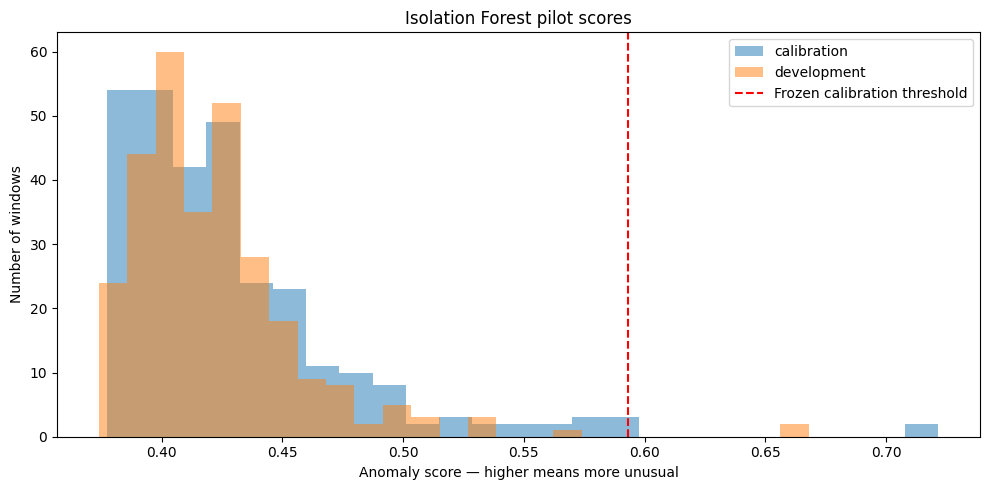

In [34]:
plt.figure(figsize=(10, 5))

for name in ["calibration", "development"]:
    plt.hist(
        baseline_scores[name],
        bins=25,
        alpha=0.5,
        label=name
    )

plt.axvline(
    baseline_threshold,
    color="red",
    linestyle="--",
    label="Frozen calibration threshold"
)

plt.xlabel("Anomaly score — higher means more unusual")
plt.ylabel("Number of windows")
plt.title("Isolation Forest pilot scores")
plt.legend()
plt.tight_layout()
plt.show()

## Save the experiment

In [33]:
import joblib
import sklearn

joblib.dump({
    "model": isolation_forest,
    "scaler": scaler,
    "threshold": baseline_threshold,
    "raw_features": FEATURES,
    "log_features": LOG_FEATURES,
    "summary_names": SUMMARY_NAMES,
    "baseline_feature_names": baseline_feature_names,
    "window_days": WINDOW_DAYS,
    "calibration_quantile": CALIBRATION_QUANTILE,
    "seed": 42,
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__
}, "isolation_forest_pilot.joblib")

for name, results in baseline_results.items():
    results.to_csv(
        f"isolation_forest_{name}_scores.csv",
        index=False
    )

score_summary.to_csv(
    "isolation_forest_score_summary.csv",
    index=False
)

files.download("isolation_forest_pilot.joblib")
files.download("isolation_forest_development_scores.csv")
files.download("isolation_forest_score_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Inspect the original readings for the flagged drive

In [35]:
FLAGGED_DRIVE = "ZHZ3PXGC"

flagged_history = (
    pilot_data.loc[
        pilot_data["serial_number"].eq(FLAGGED_DRIVE),
        ["date", "serial_number"] + FEATURES
    ]
    .sort_values("date")
    .copy()
)

print("Original SMART readings — no log transformation:")
display(flagged_history.head())
display(flagged_history.tail())

monthly_summary = (
    flagged_history
    .assign(month=flagged_history["date"].dt.to_period("M"))
    .groupby("month")[FEATURES]
    .agg(["min", "max", "median"])
)

display(monthly_summary)

Original SMART readings — no log transformation:


,date,serial_number,smart_5_raw,smart_9_raw,smart_194_raw,smart_197_raw,smart_198_raw
7830,2021-01-01,ZHZ3PXGC,2032.0,10798.0,27.0,16.0,16.0
7831,2021-01-02,ZHZ3PXGC,2032.0,10829.0,28.0,16.0,16.0
7832,2021-01-03,ZHZ3PXGC,2032.0,10845.0,28.0,16.0,16.0
7833,2021-01-04,ZHZ3PXGC,2032.0,10877.0,28.0,16.0,16.0
7834,2021-01-05,ZHZ3PXGC,2032.0,10893.0,27.0,16.0,16.0


,date,serial_number,smart_5_raw,smart_9_raw,smart_194_raw,smart_197_raw,smart_198_raw
7915,2021-03-27,ZHZ3PXGC,2032.0,12847.0,27.0,8.0,8.0
7916,2021-03-28,ZHZ3PXGC,2032.0,12863.0,28.0,8.0,8.0
7917,2021-03-29,ZHZ3PXGC,2032.0,12895.0,28.0,8.0,8.0
7918,2021-03-30,ZHZ3PXGC,2032.0,12911.0,27.0,8.0,8.0
7919,2021-03-31,ZHZ3PXGC,2032.0,12942.0,28.0,8.0,8.0


smart_5_raw                 smart_9_raw                    \
                min     max  median         min      max   median   
month                                                               
2021-01      2032.0  2032.0  2032.0     10798.0  11528.0  11163.0   
2021-02      2032.0  2032.0  2032.0     11544.0  12195.0  11870.0   
2021-03      2032.0  2032.0  2032.0     12211.0  12942.0  12577.0   

        smart_194_raw              smart_197_raw              smart_198_raw  \
                  min   max median           min   max median           min   
month                                                                         
2021-01          26.0  28.0   27.0           8.0  16.0   16.0           8.0   
2021-02          26.0  29.0   27.0           8.0   8.0    8.0           8.0   
2021-03          25.0  28.0   27.0           8.0   8.0    8.0           8.0   

                      
          max median  
month                 
2021-01  16.0   16.0  
2021-02   8.0    8.0  
2021-03   8.0    8.0

## Plot the full quarter

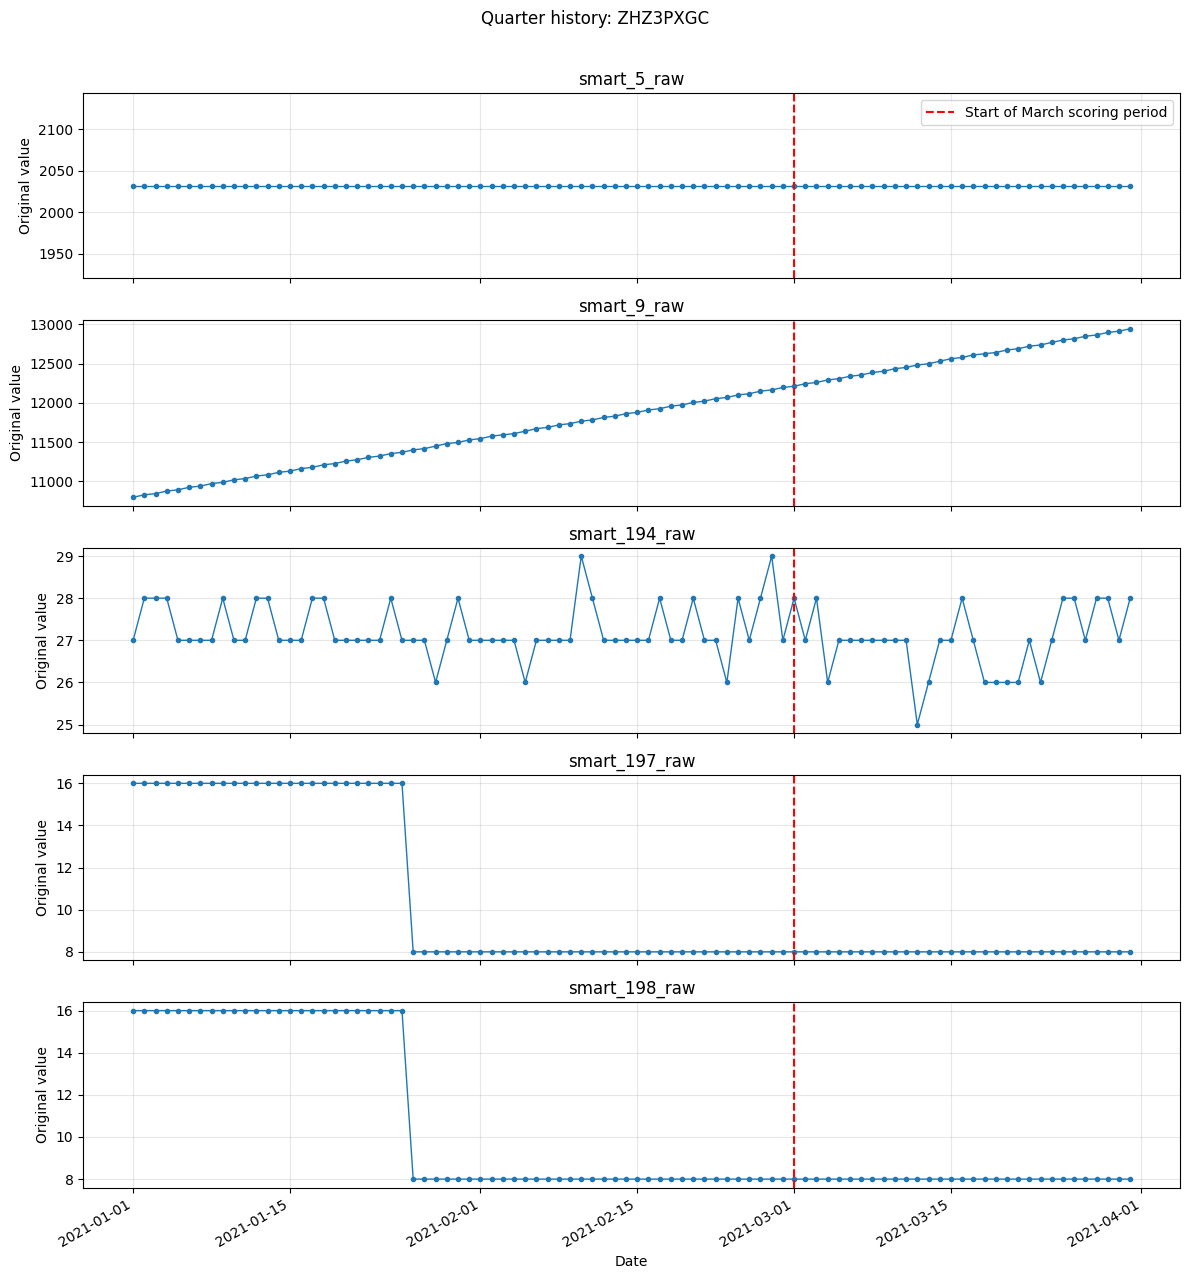

In [36]:
calendar = pd.date_range(
    flagged_history["date"].min(),
    flagged_history["date"].max(),
    freq="D"
)

plot_history = (
    flagged_history
    .set_index("date")[FEATURES]
    .reindex(calendar)
)

fig, axes = plt.subplots(
    len(FEATURES), 1,
    figsize=(12, 13),
    sharex=True
)

for ax, feature in zip(axes, FEATURES):
    ax.plot(
        plot_history.index,
        plot_history[feature],
        marker=".",
        linewidth=1
    )

    ax.axvline(
        pd.Timestamp("2021-03-01"),
        color="red",
        linestyle="--",
        label="Start of March scoring period"
    )

    ax.set_ylabel("Original value")
    ax.set_title(feature)
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Date")

fig.suptitle(f"Quarter history: {FLAGGED_DRIVE}")
fig.autofmt_xdate()
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## Create modified copies of development windows

In [37]:
original_windows = window_sets["development"]["X"]

temperature_index = FEATURES.index("smart_194_raw")

synthetic_windows = {}

# Small sustained shift over the final seven days.
modified = original_windows.copy()
modified[:, -7:, temperature_index] += 2
synthetic_windows["shift_plus_2_last_7_days"] = modified

# Larger sustained shift over the final seven days.
modified = original_windows.copy()
modified[:, -7:, temperature_index] += 5
synthetic_windows["shift_plus_5_last_7_days"] = modified

# Single spike on the final day.
modified = original_windows.copy()
modified[:, -1, temperature_index] += 10
synthetic_windows["spike_plus_10_last_day"] = modified

print("Original windows remain unchanged.")
print("Experiments:", list(synthetic_windows))

Original windows remain unchanged.
Experiments: ['shift_plus_2_last_7_days', 'shift_plus_5_last_7_days', 'spike_plus_10_last_day']


## Score them without retraining

In [38]:
original_scores = baseline_scores["development"]

sensitivity_rows = []
sensitivity_details = {}

for experiment, windows in synthetic_windows.items():
    feature_table = summarise_windows(windows)
    scaled_features = scaler.transform(feature_table)

    changed_scores = -isolation_forest.score_samples(
        scaled_features
    )

    differences = changed_scores - original_scores

    details = (
        window_sets["development"]["metadata"]
        .copy()
        .reset_index(drop=True)
    )

    details["original_score"] = original_scores
    details["modified_score"] = changed_scores
    details["score_change"] = differences
    details["original_flag"] = original_scores > baseline_threshold
    details["modified_flag"] = changed_scores > baseline_threshold

    sensitivity_details[experiment] = details

    sensitivity_rows.append({
        "experiment": experiment,
        "windows": len(windows),
        "median_score_change": np.median(differences),
        "percent_with_increased_score": (
            (differences > 1e-10).mean() * 100
        ),
        "original_flagged_windows": int(
            details["original_flag"].sum()
        ),
        "modified_flagged_windows": int(
            details["modified_flag"].sum()
        ),
        "newly_flagged_windows": int(
            (
                ~details["original_flag"]
                & details["modified_flag"]
            ).sum()
        )
    })

sensitivity_summary = pd.DataFrame(sensitivity_rows)

display(sensitivity_summary.round(4))

,experiment,windows,median_score_change,percent_with_increased_score,original_flagged_windows,modified_flagged_windows,newly_flagged_windows
0,shift_plus_2_last_7_days,294,0.0155,84.0136,2,2,0
1,shift_plus_5_last_7_days,294,0.0625,98.9796,2,7,5
2,spike_plus_10_last_day,294,0.0975,100.0000,2,8,6


Save this baseline evidence

In [39]:
sensitivity_summary.to_csv(
    "isolation_forest_synthetic_sensitivity.csv",
    index=False
)

for experiment, details in sensitivity_details.items():
    details.to_csv(
        f"isolation_forest_{experiment}.csv",
        index=False
    )

files.download("isolation_forest_synthetic_sensitivity.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>